# 07 · Front tracking on the circle

Notebooks 03–06 solved the Cauchy problem on the whole line. This one solves the same equation on a
compact domain with no boundary, the circle of circumference $L$:
$$
u_t+f_\delta(u)_x=0,\qquad x\in S^1=\mathbb R/L\mathbb Z,\qquad u(0,\cdot)=u_0^\delta .
$$
The data $u_0^\delta$ are piecewise constant with values on the flux grid, as before. Now a front that
leaves the chart $[a,a+L)$ through one end comes back through the other and can collide with the fronts
there. There are no far-field states, no boundary conditions and no inflow data. This is intrinsic
one-dimensional evolution, not a two-dimensional PDE restricted to a curve.

| claim | status |
|---|---|
| Riemann solver, front speeds and the collision rule are those of notebooks 03–04 | by construction |
| $\int_{S^1}u^\delta(t)\,dx$ is constant (no boundary flux) | exact |
| $\mathrm{TV}_{S^1}(u^\delta(t))$, counting the jump across the seam, never increases | exact (same proof as notebook 06) |
| the circle solution equals the line solution with $L$-periodic data | exact (uniqueness on $\mathbb R$); checked numerically on a finite cover in §4 |
| for convex $f$ and zero mean, $\mathrm{TV}(u(t))\sim 2L/t$ as $t\to\infty$ | proved for exact solutions (Lax 1957); observed for $u^\delta$ until $L/t$ is a few grid steps |

*Implementation: `fronttrack.periodic` (`Circle`, `PeriodicFrontTracker`).*

In [1]:
# Setup: use the local checkout if present, otherwise install from GitHub.
import os, sys, subprocess, importlib, importlib.util
from pathlib import Path
REPO = "parasuramv/scalar-front-tracking"

for candidate in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if (candidate / "fronttrack").is_dir():
        sys.path.insert(0, str(candidate))
        break
if importlib.util.find_spec("fronttrack") is None:
    # GIT_TERMINAL_PROMPT=0: fail fast instead of waiting for a password prompt.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           f"git+https://github.com/{REPO}.git"],
                          env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    importlib.invalidate_caches()
for name in ("matplotlib", "ipywidgets"):
    if importlib.util.find_spec(name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", name])
if "google.colab" in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import fronttrack
from fronttrack import DiscreteFlux, FrontTracker, solve_riemann

# One small, fixed palette for the whole series.
C_FLUX, C_POLY, C_ENV, C_EXACT = "#9a9a94", "#2a78d6", "#eb6834", "#222222"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 2})
print("fronttrack", fronttrack.__version__)

fronttrack 0.3.0


## 1. What changes on the circle

Three things change, and nothing else does.

1. **Data.** $N$ breakpoints need $N$ states, not $N+1$. State $j$ fills the arc from breakpoint $j$ to
   breakpoint $j+1$, and the last state fills the arc that wraps through the seam. So breakpoint $0$
   gets a genuine left state, the last one. A constant solution has no breakpoints and one state.
2. **Adjacency.** The fronts are kept as an ordered list of real coordinates, a *lift*, spanning at most
   one circumference. The right neighbour of the last front is the first front, one period further on.
   The collision search of notebook 04 is unchanged, except that the gap of this wraparound pair gets
   an extra $+L$.
3. **Collisions across the seam.** Before resolving a collision, the solver cuts the circular list
   inside its largest empty arc and shifts the fronts before the cut by $L$. The colliding cluster is then
   in the interior of an ordered list, and the cluster rule of notebook 04 applies verbatim.

After every step the whole lift is translated by a whole number of periods, so coordinates stay in
the chart. Individual fronts are never wrapped one at a time, so their order is never re-sorted.

In [3]:
from fronttrack import Circle, PeriodicFrontTracker
from fronttrack.visualization import observe_tracker, plot_spacetime

burgers = DiscreteFlux(lambda u: 0.5 * u**2, np.linspace(-1, 1, 41))
coarse = DiscreteFlux(lambda u: 0.5 * u**2, np.linspace(-1, 1, 5))   # few fronts, easy to print
tr = PeriodicFrontTracker.from_values(coarse, [0.0, 0.5], [1.0, -1.0])
for f in tr.snapshot():
    print(f"x = {f.x:.2f}   u: {coarse.u_grid[f.iL]:+.2f} -> {coarse.u_grid[f.iR]:+.2f}   speed {f.speed:+.3f}")
print("u at the seam x=0, x=1, x=-1:", tr.sample([0.0, 1.0, -1.0]))

x = 0.00   u: -1.00 -> -0.50   speed -0.750
x = 0.00   u: -0.50 -> +0.00   speed -0.250
x = 0.00   u: +0.00 -> +0.50   speed +0.250
x = 0.00   u: +0.50 -> +1.00   speed +0.750
x = 0.50   u: +1.00 -> -1.00   speed +0.000
u at the seam x=0, x=1, x=-1: [1. 1. 1.]


The jump at $x=0$ goes from $-1$ (the state that wraps through the seam) to $+1$, so it is a
rarefaction fan: four fronts at the same point, one per grid step, ordered by speed. The jump at $x=1/2$ is a shock with speed $0$. Sampling is right-continuous and
$L$-periodic, so $x=0$, $1$ and $-1$ all return the state to the right of the seam.

## 2. Transport through many circuits

For an affine flux $f(u)=cu+d$ every front moves at speed $c$ and nothing collides. The exact solution
is $u_0(x-ct)$ on the circle. With $L=2$ and $t=23.125$, speed $c=2$ means $23\tfrac18$ circuits and
$c=-3$ means $34\tfrac{11}{16}$ circuits the other way. The sampled solution must equal the shifted data
to the last bit.

In [4]:
for c in (-3.0, 2.0):
    flux = DiscreteFlux(lambda u: c * u + 2, [-1, 0, 1])
    make = lambda: PeriodicFrontTracker.from_values(flux, [-2, -1.7, -0.8], [0, 1, -1],
                                                     domain=Circle(length=2, origin=-2))
    tr, initial = make(), make()
    tr.run(23.125)
    x = np.linspace(-4.9997, 4.9997, 600)
    err = np.max(np.abs(tr.sample(x) - initial.sample(x - c * 23.125)))
    print(f"c = {c:+}: circuits = {abs(c) * 23.125 / 2:.4f}, events = {tr.event_count}, max error = {err}")

c = -3.0: circuits = 34.6875, events = 0, max error = 0.0
c = +2.0: circuits = 23.1250, events = 0, max error = 0.0


## 3. A collision across the seam

Burgers data $-1, 1, 0$ on the arcs starting at $0.2$, $0.5$, $0.8$. The jump at $0.2$ is the last
state $0$ against $-1$: a shock moving left at speed $-1/2$. The jump at $0.8$ is $1$ against $0$: a shock
moving right at speed $1/2$. They approach each other *through the seam* and meet at $t=0.4$. The
jump at $0.5$ is a rarefaction fan that the shocks do not reach before $t=0.4$.

The space–time plot draws the exact recorded front paths. A path that crosses the seam is split there,
so no false diagonal crosses the picture. Rotating the data must commute with the evolution; the last
line checks this.

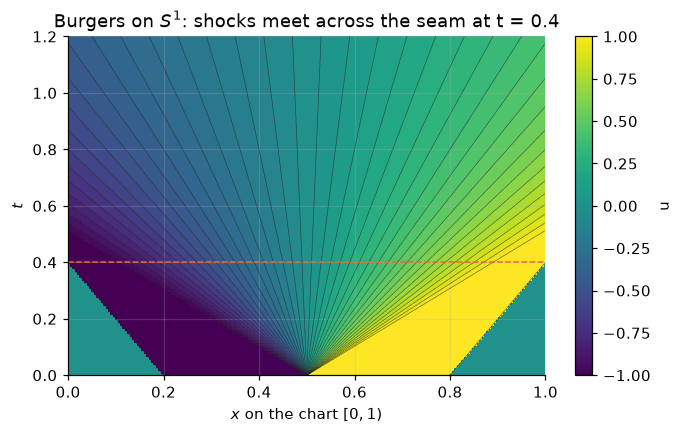

events by t=0.4: 1   rotation mismatch: 0.0


In [5]:
make = lambda: PeriodicFrontTracker.from_values(burgers, [0.2, 0.5, 0.8], [-1, 1, 0], record_history=True)
history = observe_tracker(make(), np.linspace(0, 1, 401), np.linspace(0, 1.2, 121))
fig, ax = plt.subplots(figsize=(7, 4))
plot_spacetime(history, ax=ax)
ax.axhline(0.4, color=C_ENV, lw=1, ls="--")
ax.set(xlabel="$x$ on the chart $[0,1)$", ylabel="$t$", title="Burgers on $S^1$: shocks meet across the seam at t = 0.4")
plt.show()

a = make().run(0.4)
b = PeriodicFrontTracker.from_values(burgers, [0.17, 0.57, 0.87], [0, -1, 1]).run(0.4)  # rotated by 0.37
x = np.linspace(0.0013, 0.9991, 777)
print("events by t=0.4:", a.event_count, "  rotation mismatch:", np.max(np.abs(a.sample(x) - b.sample(x + 0.37))))

## 4. The circle solver against the line solver

An $L$-periodic function on $\mathbb R$ is a function on $S^1$, and the entropy solution on $\mathbb R$ with
periodic data stays periodic, by uniqueness. So the circle solver should agree with the line solver
of notebook 04 applied to repeated copies of the data.

The line solver needs data that are constant at $\pm\infty$, so we can only repeat the data finitely
often. Waves travel at most at speed $\max|f_\delta'|$, so with $2K+1$ copies the waves coming from the
ends of the cover cannot reach the middle period before time $KL/\max|f_\delta'|$. Up to that time the two
solvers must agree on $[0,L)$. This is a numerical check of two independent drivers, not a proof.

In [6]:
cubic = DiscreteFlux(lambda u: u**3 / 3, np.linspace(-1, 1, 21))   # nonconvex, speeds |f'| <= 1
rng = np.random.default_rng(7)
worst = 0.0
for trial in range(50):
    p = np.sort(rng.uniform(0, 1, 6))
    v = cubic.u_grid[rng.integers(0, 21, 6)]
    K, T = 4, 1.3                                     # ends cannot reach [0,1) before t = 4
    cover_p = np.concatenate([k + p for k in range(-K, K + 1)])
    cover_v = np.r_[v[-1], np.tile(v, 2 * K + 1)]
    x = np.linspace(0.000123, 0.999877, 1000)
    line = FrontTracker.from_values(cubic, cover_p, cover_v).run(T).sample(x)
    circle = PeriodicFrontTracker.from_values(cubic, p, v).run(T).sample(x)
    worst = max(worst, np.max(np.abs(line - circle)))
print("largest difference over 50 random data:", worst)

largest difference over 50 random data: 0.0


## 5. Decay on a compact domain

On the circle there is nowhere for the waves to go, so they keep colliding. For a convex flux this makes
every solution decay to its mean, and fast.

**Theorem (Lax, 1957).** Let $f$ be uniformly convex, $u_0$ bounded and $L$-periodic with mean $\bar u$.
Then the entropy solution satisfies $\lVert u(t)-\bar u\rVert_{L^\infty}=O(1/t)$. For Burgers with
$\bar u=0$ the profile becomes a sawtooth of slope $1/t$ with one shock per period of height $L/t$, so
$\mathrm{TV}_{S^1}(u(t))\sim 2L/t$.

Compare the whole line. Data with compact support and zero mass typically decay to an N-wave, whose
height and total variation decay only like $t^{-1/2}$. The plot runs both with the same bump
$-\sin(2\pi x)$ on one period. On the circle the bump is repeated forever. On the line it sits among
zeros: its negative half moves left, its positive half moves right, and they separate.

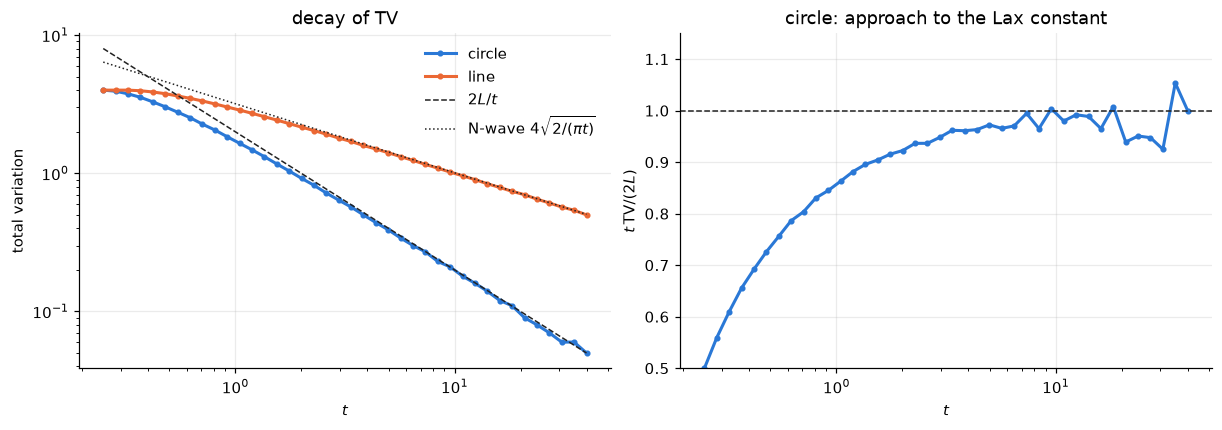

circle mass drift up to t = 40: 8.9e-16;  grid step = 0.0025


In [7]:
fine = DiscreteFlux(lambda u: 0.5 * u**2, np.linspace(-1, 1, 801))
bump = lambda x: -np.sin(2 * np.pi * x)
circle = PeriodicFrontTracker.from_function(fine, bump, cells=400)
edges = np.arange(401) / 400
mid = (edges[:-1] + edges[1:]) / 2
line = FrontTracker.from_values(fine, edges, np.r_[0.0, bump(mid), 0.0])
mass0 = circle.integral()
ts = np.geomspace(0.25, 40, 40)
tv_c, tv_l, drift = [], [], 0.0
for t in ts:
    circle.run(t); line.run(t)
    tv_c.append(circle.total_variation()); tv_l.append(line.total_variation())
    drift = max(drift, abs(circle.integral() - mass0))
tv_c, tv_l = np.array(tv_c), np.array(tv_l)

fig, (p, q) = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
p.loglog(ts, tv_c, "o-", ms=3, color=C_POLY, label="circle")
p.loglog(ts, tv_l, "o-", ms=3, color=C_ENV, label="line")
p.loglog(ts, 2 / ts, "--", color=C_EXACT, lw=1, label="$2L/t$")
p.loglog(ts, 4 * np.sqrt(2 / (np.pi * ts)), ":", color=C_EXACT, lw=1, label=r"N-wave $4\sqrt{2/(\pi t)}$")
p.set(xlabel="$t$", ylabel="total variation", title="decay of TV")
p.legend(frameon=False)
q.semilogx(ts, ts * tv_c / 2, "o-", ms=3, color=C_POLY)
q.axhline(1, color=C_EXACT, lw=1, ls="--")
q.set(xlabel="$t$", ylabel=r"$t\,\mathrm{TV}/(2L)$", title="circle: approach to the Lax constant", ylim=(0.5, 1.15))
plt.show()
print(f"circle mass drift up to t = 40: {drift:.1e};  grid step = {fine.u_grid[1] - fine.u_grid[0]:.4f}")

The circle curve follows $2L/t$. The line curve approaches the N-wave value $4\sqrt{2/(\pi t)}$: the bump has
positive and negative parts of mass $p=q=1/\pi$, and an N-wave has jumps $\sqrt{2p/t}$ and $\sqrt{2q/t}$. In the right panel $t\,\mathrm{TV}/(2L)$
climbs towards $1$ and then fluctuates by a few percent. At time $t$ the sawtooth spans only about
$L/(t\delta)$ grid steps, and each collision changes the total variation by a multiple of $\delta$, so the
relative jumps grow like $t\delta/L$. That is a property of $f_\delta$, not of the circle: the theorem is about $f$.

The sign of the bump matters on the line. With $+\sin(2\pi x)$ the positive half runs into the negative half
instead of away from it; then no N-wave forms, and the line solution is exactly the circle's sawtooth on
$[0,1]$, decaying like $1/t$ too.

## 6. Try it yourself

Pick a flux and smooth periodic data. The data are sampled at cell midpoints and rounded to the flux grid
(not cell averages). The left panel shows the profile at three times, the right panel the space–time
picture with the exact front paths. The sliders work only in Jupyter or Colab.

Static preview at the default settings. Run this cell in Jupyter or Colab to get the sliders.


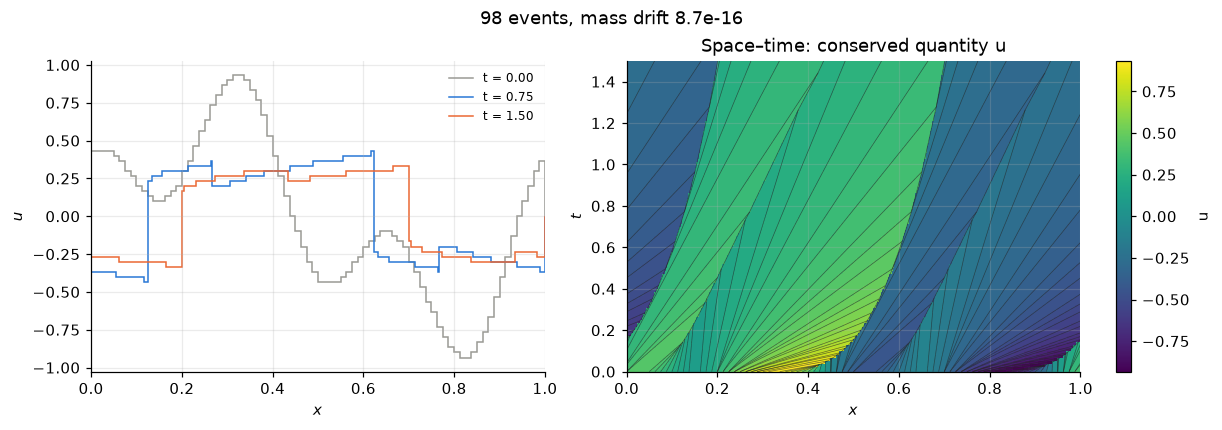

In [8]:
import ipywidgets as widgets
FLUXES = {"Burgers u²/2": lambda u: 0.5 * u**2, "cubic u³": lambda u: u**3,
          "concave -u²/2": lambda u: -0.5 * u**2, "sin 3u": lambda u: np.sin(3 * u)}
DATA = {"sin 2πx": lambda x: np.sin(2 * np.pi * x),
        "two modes": lambda x: 0.6 * np.sin(2 * np.pi * x) + 0.4 * np.cos(6 * np.pi * x),
        "box": lambda x: np.where((x > 0.25) & (x < 0.6), 0.9, -0.3)}
controls = dict(
    flux=widgets.Dropdown(options=list(FLUXES), value="cubic u³", description="flux"),
    data=widgets.Dropdown(options=list(DATA), value="two modes", description="data"),
    nodes=widgets.IntSlider(value=61, min=5, max=201, step=4, description="nodes"),
    T=widgets.FloatSlider(value=1.5, min=0.1, max=5, step=0.1, description="T"))
def show(flux, data, nodes, T):
    fl = DiscreteFlux(FLUXES[flux], np.linspace(-1, 1, nodes))
    tr = PeriodicFrontTracker.from_function(fl, DATA[data], cells=80, record_history=True)
    mass = tr.integral()
    h = observe_tracker(tr, np.linspace(0, 1, 401), np.linspace(0, T, 101))
    fig, (p, q) = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
    for k, c in zip((0, 50, 100), (C_FLUX, C_POLY, C_ENV)):
        e, v = h.profiles[k]
        p.stairs(v, e, color=c, label=f"t = {h.times[k]:.2f}")
    p.set(xlabel="$x$", ylabel="$u$", xlim=(0, 1))
    p.legend(frameon=False, fontsize=8)
    plot_spacetime(h, ax=q)
    q.set(xlabel="$x$", ylabel="$t$")
    fig.suptitle(f"{tr.event_count} events, mass drift {tr.integral() - mass:.1e}")
    plt.show()
display(widgets.HBox(list(controls.values()), layout=widgets.Layout(flex_flow="row wrap")),
        widgets.interactive_output(show, controls))

## References

* P. D. Lax, Hyperbolic systems of conservation laws II, *Comm. Pure Appl. Math.* **10** (1957) 537–566.
* C. M. Dafermos, Polygonal approximations of solutions of the initial value problem for a
  conservation law, *J. Math. Anal. Appl.* **38**(1) (1972) 33–41.
* H. Holden, N. H. Risebro, *Front Tracking for Hyperbolic Conservation Laws*, 2nd ed.,
  Springer (2015), Ch. 2.

---
**03** built the Riemann solver, **04** the event loop, **05** measured convergence, **06** stability, and
this notebook moved the whole construction to the circle without changing any of it.